# Reto: Planta Física - Avance 1: Investigación

**Clave del curso:** MA2015


**Grupo:** 201


**Equipo:** 04


**Integrantes:**

    * Alexandra Natalie Morales Brust   A01661867

    * Axel Rodrigo Vélez Robles         A01668768

    * Leonardo Roldan Perez             A01661235


**Registro de Rotación y Colaboración:**

    * Programación: Alexandra (hizo la explicación de la primera parte y comprobó los calculos de Axel)

    * Revisión: Axel (hizo el calculo manual y corroboro la explicación de la primera parte)

    *Verificación: Leonardo (Realizó la verificación final del entregable, confirmando que estuviera completo. Hizo el repositorio.)



## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [20]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

### 1.1 Formulación y Supuesto del modelo
#### A. Decisión física y significado de los genes
El modelo busca optimizar la distribución mensual tanto de agua tratada como de agua potable para los edificios del campus. Primero se define un cromosoma $k = (k_1, k_2, k_3, k_4)$ con cuatro niveles enteros, cada una de estas unidades equivale a diez puntos porcentuales de reúso.
La fracción de reuso es:
* $x_i = \frac{k_i}{10}$ nuestro porcentaje es $100x_i$.

El orden estricto de los edificios es:
1. **$k_1$:** Aulas 1
2. **$k_2$:** Biblioteca
3. **$k_3$:** Cedetec
4. **$k_4$:** Aulas 2 

#### B. Datos observados, dominios y capacidades

Tomamos los consumos de **marzo de 2025** con una demanda total $Q = 2276.21\text{ m}^3$. Adoptamos una capacidad máxima de almacenamiento como supuesto didáctico de $C = 1410\text{ m}^3$.

| Edificio | Mes | Demanda $D_i$ ($\text{m}^3$) | Dominio de $k_i$ | $x_i = \frac{k_i}{10}$ máximo | Reúso Máximo |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Aulas 1** | Marzo 2025 | 847.00 | $\{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ | 0.8 | 80% |
| **Biblioteca** | Marzo 2025 | 462.00 | $\{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ | 0.8 | 80% |
| **Cedetec**| Marzo 2025 | 284.21 | $\{0, 1, 2, 3, 4, 5, 6\}$ | 0.6 | 60% |
| **Aulas 2** | Marzo 2025 | 683 |$\{0,1,2,3,4,5,6,7,8\}$ | 0.8 | 80% |
| **Total Q** | Marzo 2025 | 2276.21 | -------------- | ----| --- |

#### C. Objetivo, fórmulas y dirección de aptitud
* **Volúmenes por edificio:** $T_i = D_i \frac{k_i}{10}$  , $P_i = D_i - T_i$
* **Totales del sistema:** $T = \sum T_i$  , $P = Q - T$,   $E = \max(0, T - C)$
* **Objetivo:** Minimizar el agua potable ($P$) y la aptitud $F(k)$, donde un menor valor indica mejor candidato.
$$F(k) = \begin{cases} \frac{P}{Q}, & T \le C \\ 1 + \frac{E}{C}, & T > C \end{cases}$$

  * $T_i = D_i \frac{k_i}{10}$ (agua tratada asignada según el gen).
  * $P_i = D_i - T_i$ (agua potable remanente).

  * $T = \sum T_i$ (total de agua tratada).
  * $P = Q - T$ (total de agua potable).
  * $E = \max(0, T - C)$ (exceso si se supera la capacidad $C = 1410\text{ m}^3$).

  *Un candidato se considera factible si el exceso cumple con la tolerancia $E \le 10^{-8}\text{ m}^3$*.

#### D. Naturaleza de los datos: Observados vs. Supuestos Didácticos
* **Datos observados (Demandas $D_i$):** 
  * Los consumos reales de agua registrados en el campus durante **marzo de 2025** ($Q = 2276.21\text{ m}^3$). Se utilizan como una base inalterable porque representan la necesidad real de abastecimiento que el sistema debe cubrir mes con mes.
* **Supuestos didácticos (Capacidad $C$ y Máximos de Reúso):** 
  * *La capacidad máxima de almacenamiento de $C = 1410\text{ m}^3$ y los reusos Maximos (80% para Aulas 1 y 2/Biblioteca y 60% para Cedetec) no son mediciones fijas de una infraestructura real, sino mas bien supuestos que fueron impuestos para el reto. Sirven para limitar el sistema, generando un conflicto de optimización, obliga a los algoritmos a buscar combinaciones y penalizar los planes que rebasen los límites operativos del campus.
* **Alcance de los supuestos:** 
  * El análisis se basa solamente en el mes de marzo de 2025, omitiendo el comportamiento de otros meses, solo ayuda a ver el comportamiento del algoritmo. 

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [21]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [22]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

### Cálculo Manual

#### Candidato 1

Con el candidato $k=(6,6,6,6)$, se usan las fórmulas:

$T_i = D_i \frac{k_i}{10}$ \
$P_i = D_i - T_i$

para calcular $T_i$ (Agua tratada) y $P_i$ (Agua potable) para cada edificio.

- **Aulas 1** \
$T_1 = 847.00\times \frac{6}{10} = 508.2$ m³ \
$P_1 = 847.00 - 508.2 = 338.8$ m³

- **Biblioteca** \
$T_2 = 462.00\times \frac{6}{10} = 277.2$ m³ \
$P_2 = 462.00 - 277.2 = 184.8$ m³

- **Cedetec** \
$T_3 = 284.21\times \frac{6}{10} = 170.526$ m³ \
$P_3 = 284.21 - 170.526 = 113.684$ m³

- **Aulas 2** \
$T_4 = 683.00\times \frac{6}{10} = 409.8$ m³ \
$P_4 = 683.00 - 409.8 = 273.2$ m³

##### Cálculo de totales

- **Agua tratada** \
$T = T_1+T_2+T_3+T_4 = 508.2 + 277.2 + 170.526 + 409.8 = 1365.726$ m³

- **Agua potable** \
$P = Q - T = 2276.21 - 1365.726 = 910.484$ m³

##### Capacidad y Exceso

1365.726 < 1410, es factible
$E = max(0 , 1365.726 - 1410) = 0$ m³

##### Aptitud

$F = \frac{910.484}{2276.21} = 0.4$

#### Candidato 2

Con el candidato $k=(8,8,6,8)$, se usan las fórmulas:

$T_i = D_i \frac{k_i}{10}$ \
$P_i = D_i - T_i$

para calcular $T_i$ (Agua tratada) y $P_i$ (Agua potable) para cada edificio.

- **Aulas 1** \
$T_1 = 847.00\times \frac{8}{10} = 677.6$ m³ \
$P_1 = 847.00 - 677.6 = 169.4$ m³

- **Biblioteca** \
$T_2 = 462.00\times \frac{8}{10} = 369.6$ m³ \
$P_2 = 462.00 - 369.6 = 92.4$ m³

- **Cedetec** \
$T_3 = 284.21\times \frac{6}{10} = 170.526$ m³ \
$P_3 = 284.21 - 170.526 = 113.684$ m³

- **Aulas 2** \
$T_4 = 683.00\times \frac{8}{10} = 546.4$ m³ \
$P_4 = 683.00 - 546.4 = 136.6$ m³

##### Cálculo de totales

- **Agua tratada** \
$T = T_1+T_2+T_3+T_4 = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126$ m³

- **Agua potable** \
$P = Q - T = 2276.21 - 1764.126 = 512.084$ m³

##### Capacidad y Exceso

1764.126 > 1410, no es factible
$E = max(0 , 1764.126 - 1410) = 354.126$ m³

##### Aptitud

$F = 1 + \frac{354.126}{1410} = 1.2511$

### Comparación con función evaluate()

In [ ]:
print("Candidato 1: ", candidato1)
candidato1 = np.array([6, 6, 6, 6])
evaluacion1 = evaluate(candidato1)
print("Candidato 1: ", candidato1)
print(evaluacion1)

print("Candidato 2: ", candidato2)
candidato2 = np.array([8, 8, 6, 8])
evaluacion2 = evaluate(candidato2)
print("Candidato 1: ", candidato2)
print(evaluacion2)

NameError: name 'np' is not defined

### Interpretación

Los resultados de los cálculos manuales resultaron iguales a los de la función de evaluate, porque la función hace las mismas operaciones que se hacen a mano

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [23]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [24]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [25]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [26]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [27]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [28]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [29]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

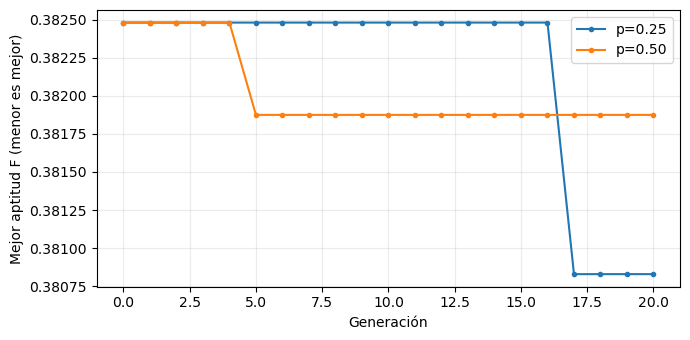

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

El parámetro que cambia es la probabilidad de mutación de 0.25 a 0.50.
Los parámetros de población y semilla se quedan igual

Los dos candidatos son factibles y usan casi por completo la capacidad límite

La gráfica de la base tiene un F menor por 0.0010, es igual a 2.379 m³ menos del agua potable. Esto representa un 0.1 % de la demanda total.

Ambas gráficas empiezan con el mismo F igual a 0.3825. La base no presenta ningún cambio hasta la generación 16 y se mejora en la 17, con un valor de 0.3808.

Mientras que, la variación presenta una mejora desde la 4ta generación con un valor de 0.3819, y ya de ahí no cambia.

En el caso de dos ejecuciones no presenta un cambio significante para indicar que la probabilidad de mutación es mejor, con una diferencia de 0.001 en F.

Los genes graficados hacen volúmenes muy similares, con muchas semillas se podría repetir más veces.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [31]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

 ## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.